In [143]:
import numpy as np
import pandas as pd
from numpy.ma import masked_array

from astropy.visualization import make_lupton_rgb
import matplotlib.pyplot as plt
import matplotlib.ticker as plticker
import ast

from matplotlib.colors import ListedColormap

import torch

In [144]:
path_test = '' # 'Exp/model_exp6/'
data = np.load(path_test + 'testing_arrays.npz')
original, segmented, labels = data['Original'], data['Segmented'], data['Labels']

data = pd.read_csv(path_test + 'testing_data.csv')
data['Per_class_dice'] = data['Per_class_dice'].apply(ast.literal_eval)
print(len(data))
data.head()

4000


,Y6_COADD_OBJECT_ID,HPIX_16384,HPIX_4096,DNF_ZMEAN_SOF,RA,DEC,FLUX_RADIUS_G,FLUX_RADIUS_R,FLUX_RADIUS_I,FLUX_RADIUS_Z,...,SKYBRITE_WMEAN_Z,Z1,LENSED_MAG,mag_1,ISOLATION,EINSTEIN_RADIUS,MAGNIFICATION,POSITION1,Accuracy,Per_class_dice
0,1.267659e+09,1.158003e+09,72375212.0,0.525733,35.367990,-7.019900,3.976956,3.282353,2.832310,2.924878,...,8077.319824,1.245358,20.196593,22.223032,0.623344,2.973736,6.465106,3.858517,0.930209,"[0.9395409226417542, 0.938906729221344, 0.8582..."
1,1.135978e+09,1.182569e+09,73910574.0,0.778999,16.653025,2.930162,2.747880,3.192030,2.783931,2.815581,...,6490.529785,1.724290,20.129872,22.383993,0.931760,3.205138,7.973491,3.802568,0.913043,"[0.9271708726882935, 0.977667510509491, 0.7565..."
2,1.258367e+09,1.158519e+09,72407416.0,0.557048,34.339025,-5.954960,3.211615,3.062615,2.813792,2.963492,...,7839.560059,1.666688,20.028712,22.272886,0.998485,4.691870,7.900777,5.754010,0.949939,"[0.9297573566436768, 0.9854469895362854, 0.897..."
3,1.239214e+09,1.172731e+09,73295670.0,0.554187,32.009924,4.889262,3.481387,3.442901,3.385726,3.413404,...,8315.650391,1.415791,21.023803,22.619440,0.623997,1.384317,4.347652,1.808775,0.954582,"[0.9387145042419434, 0.8823529481887817, 1.0, ..."
4,1.241282e+09,1.159819e+09,72488716.0,0.664093,31.987411,-5.936059,4.032942,3.416020,2.882154,3.162258,...,7968.189941,1.543202,20.569432,22.645729,0.988232,3.797998,6.768911,4.881104,0.723714,"[0.9554716944694519, 0.9496123790740967, 0.0, ..."


In [145]:
#Printing accuracy on test sample
dict_classes = {'0': 'Source', '1': 'Deflector', '2': 'Contaminants', '3': 'Sky'}
print('Overall Dice Score: {:0.3f}'.format(data['Accuracy'].mean()))

mean_per_class = np.stack(data['Per_class_dice'].values).mean(axis=0)

for i in range(len(mean_per_class)):
    print('Per-class Dice Score {}: {:0.3f}'.format(dict_classes[str(i)], mean_per_class[i]))

Overall Dice Score: 0.918
Per-class Dice Score Source: 0.936
Per-class Dice Score Deflector: 0.954
Per-class Dice Score Contaminants: 0.795
Per-class Dice Score Sky: 0.986


In [146]:
def plot_results(image, label, pred_label):
    loc = plticker.MultipleLocator(base=3.75)
    fig, ax = plt.subplots(figsize=(15, 4), ncols=3)

    rgb = make_lupton_rgb(image[2], image[1], image[0], Q=11., stretch=40.)
    rgb = np.flipud(rgb)
    ax[0].set_title('Original Image')
    ax[0].xaxis.set_ticklabels([])
    ax[0].yaxis.set_ticklabels([])
    ax[0].imshow(rgb, aspect='equal')
    ax[0].set_xticks([])
    ax[0].set_yticks([])

      # training image (also transformed)
    thresh=0.
    source = np.ma.masked_less_equal(label[:, :, 0], thresh)
    lens = masked_array(label[:, :, 1], label[:, :, 1]!=1) # when lens is 1 show lens
    noise = masked_array(label[:, :, 2], label[:, :, 2]!=1)  # when noise is 1 show noise

    ax[1].set_facecolor('black')
    ax[1].set_title('True Label')
    ax[1].imshow(source, cmap=ListedColormap(['darkturquoise']), interpolation='nearest',  origin='lower')
    ax[1].imshow(lens,   cmap=ListedColormap(['goldenrod']),     interpolation='bilinear', origin='lower')
    ax[1].imshow(noise,  cmap=ListedColormap(['orchid']),        interpolation='bilinear', origin='lower')
    ax[1].set_xticks([])
    ax[1].set_yticks([])
    #ax[1].axis('off')
    

    thresh=0.5
    source = np.ma.masked_less_equal(pred_label[0, :, :], thresh)
    lens   = np.ma.masked_less_equal(pred_label[1, :, :], thresh)
    noise  = np.ma.masked_less_equal(pred_label[2, :, :], thresh)
    
    ax[2].set_title('Predicted Label')
    ax[2].imshow(source, cmap=ListedColormap(['darkturquoise']), interpolation='nearest',  origin='lower')
    ax[2].imshow(lens,   cmap=ListedColormap(['goldenrod']),     interpolation='bilinear', origin='lower')
    ax[2].imshow(noise,  cmap=ListedColormap(['orchid']),        interpolation='bilinear', origin='lower')
    ax[2].set_xticks([])
    ax[2].set_yticks([])
    #ax[2].axis('off')
    ax[2].set_facecolor('black')



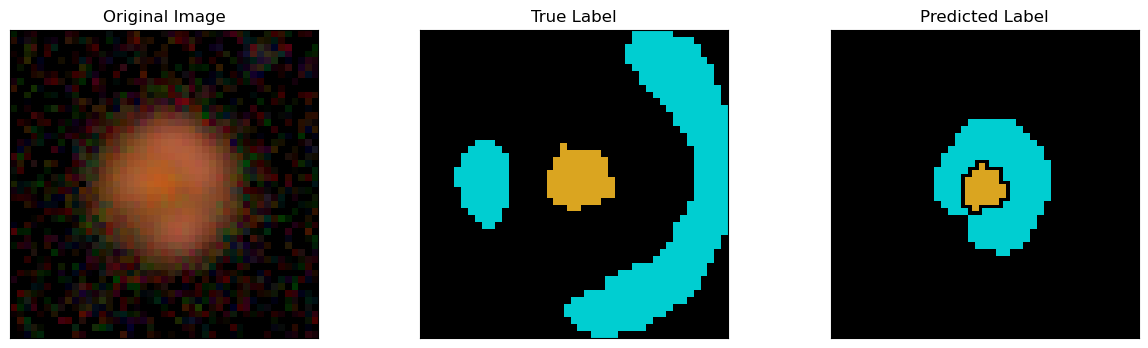

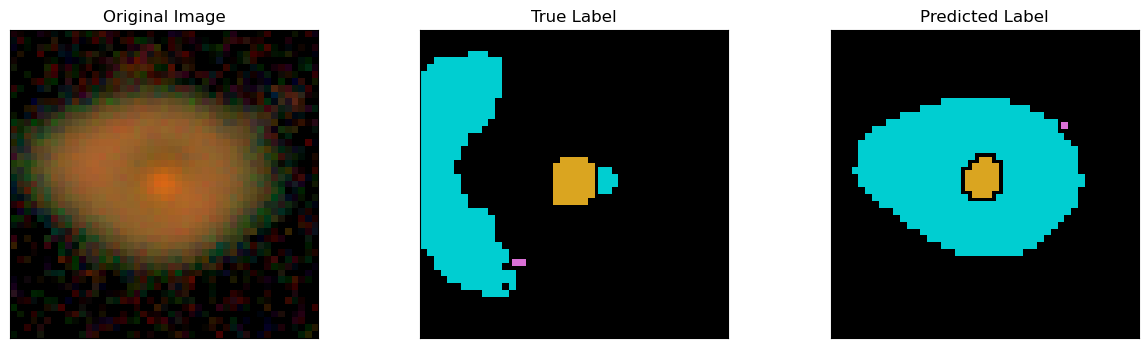

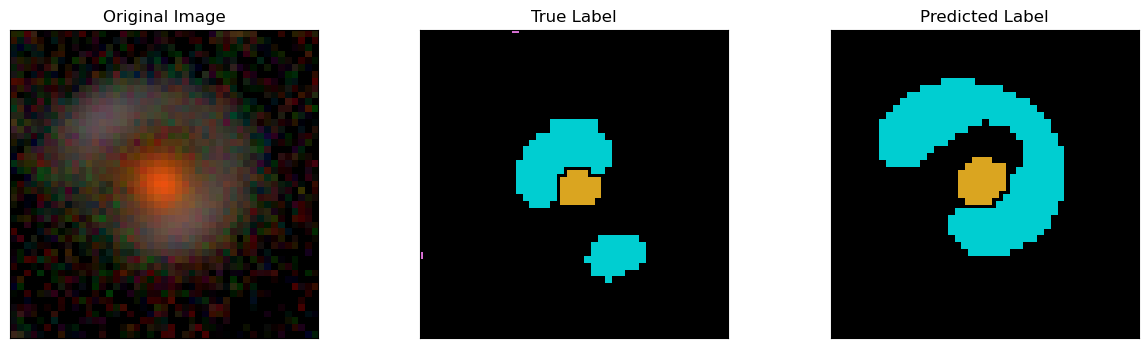

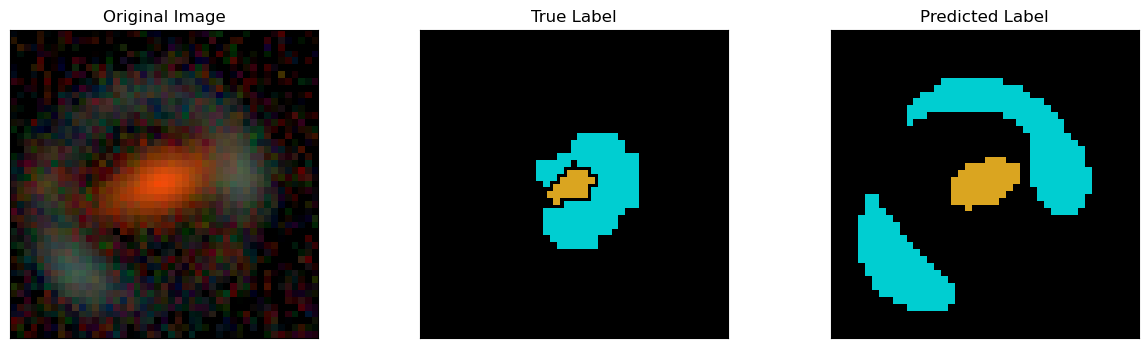

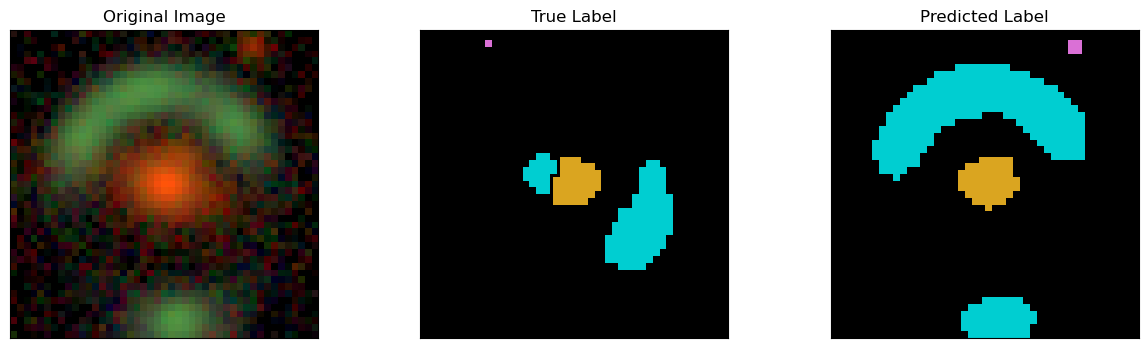

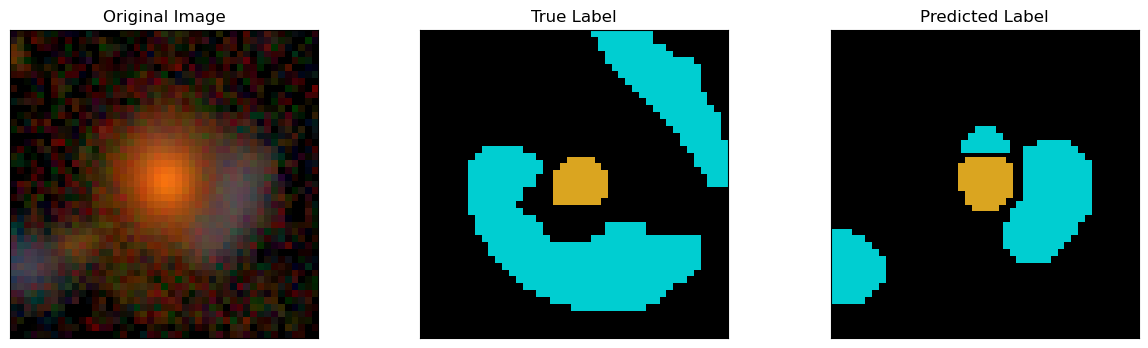

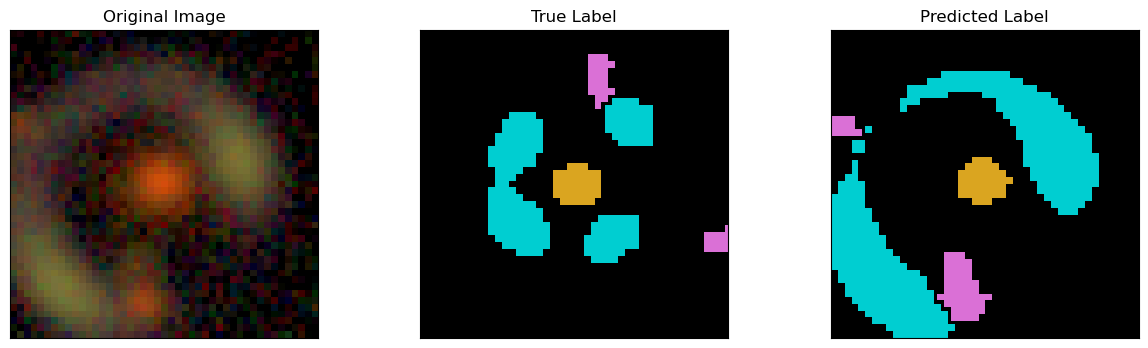

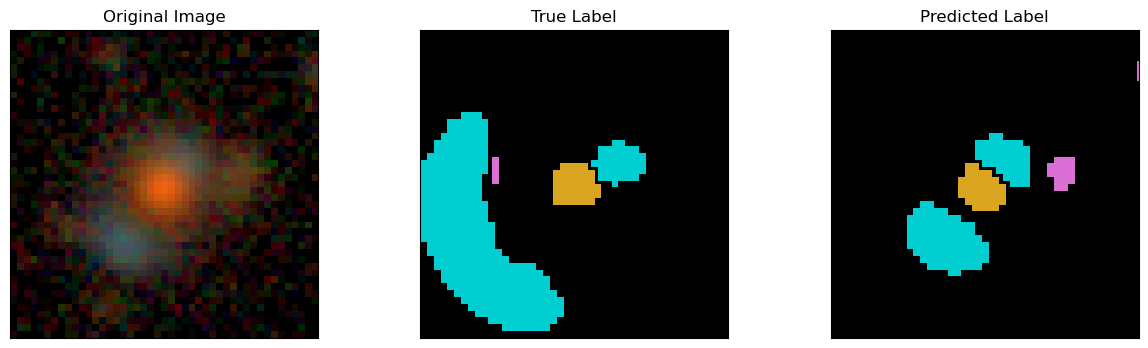

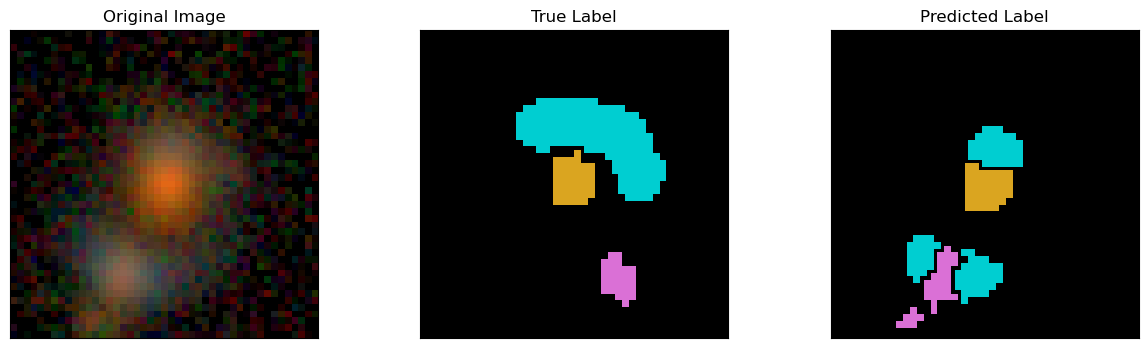

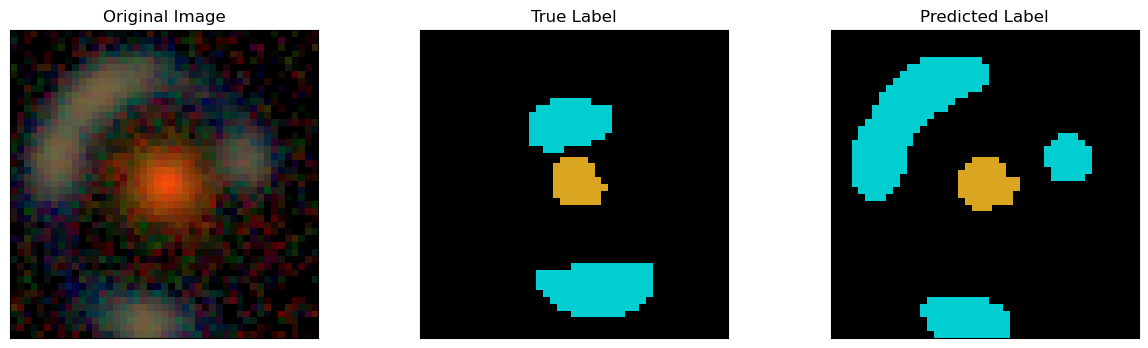

In [147]:
# Worst performing sample
N_fig = 10
best_idx = data['Accuracy'].nsmallest(N_fig).index
#best_idx = np.random.randint(0, len(data), N_fig)
img_tmp, segmented_tmp, labels_tmp = original[best_idx], segmented[best_idx], labels[best_idx]
for i in range(N_fig):
    plot_results(img_tmp[i], labels_tmp[i], segmented_tmp[i])